# Historical-Average Baseline for METR-LA Traffic-Speed Forecasting

This notebook implements a historical-average baseline using the average speed for each sensor at the same day of week and time of day. The model is evaluated at 15-, 30-, and 60-minute forecasting horizons using MAE, RMSE, and MAPE.

### Imports and paths

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "/content/metr-la.h5"
RESULTS_DIR = "/content/historical_average_results"

os.makedirs(RESULTS_DIR, exist_ok=True)

### Load and split the dataset

In [3]:
from google.colab import files
import os

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))

Saving metr-la.h5 to metr-la.h5
Uploaded files: ['metr-la.h5']


In [4]:
DATA_PATH = "/content/metr-la.h5"

print("File exists:", os.path.exists(DATA_PATH))
print("File size:", os.path.getsize(DATA_PATH), "bytes")

File exists: True
File size: 57038056 bytes


In [5]:
import pandas as pd

traffic_df = pd.read_hdf(DATA_PATH)
traffic_df.index = pd.to_datetime(traffic_df.index)

n = len(traffic_df)

train_end = int(n * 0.70)
val_end = train_end + int(n * 0.10)

train_df = traffic_df.iloc[:train_end].copy()
val_df = traffic_df.iloc[train_end:val_end].copy()
test_df = traffic_df.iloc[val_end:].copy()

print("Full dataset:", traffic_df.shape)
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

Full dataset: (34272, 207)
Training: (23990, 207)
Validation: (3427, 207)
Testing: (6855, 207)


### Handle missing values

In [6]:
# In METR-LA, zero values represent missing sensor readings.
train_clean = train_df.replace(0, np.nan)
test_clean = test_df.replace(0, np.nan)

print("Training missing values:",
      int(train_clean.isna().sum().sum()))

Training missing values: 354180


### Calculate historical averages

In [7]:
train_keys = pd.DataFrame({
    "day_of_week": train_clean.index.dayofweek,
    "hour": train_clean.index.hour,
    "minute": train_clean.index.minute
}, index=train_clean.index)

historical_average = (
    train_clean
    .groupby([
        train_keys["day_of_week"],
        train_keys["hour"],
        train_keys["minute"]
    ])
    .mean()
)

sensor_average = train_clean.mean()

print("Historical-average table shape:",
      historical_average.shape)

Historical-average table shape: (2016, 207)


### Generate predictions

In [8]:
def generate_historical_predictions(target_index):
    target_keys = pd.DataFrame({
        "day_of_week": target_index.dayofweek,
        "hour": target_index.hour,
        "minute": target_index.minute
    }, index=target_index)

    predictions = []

    for _, row in target_keys.iterrows():
        key = (
            row["day_of_week"],
            row["hour"],
            row["minute"]
        )

        if key in historical_average.index:
            prediction = historical_average.loc[key]
        else:
            prediction = sensor_average

        predictions.append(prediction.values)

    return np.asarray(predictions)


predictions = generate_historical_predictions(test_df.index)
actual = test_clean.values

print("Predictions shape:", predictions.shape)
print("Actual shape:", actual.shape)

Predictions shape: (6855, 207)
Actual shape: (6855, 207)


### Define evaluation metrics

In [9]:
def calculate_metrics(y_true, y_pred):
    mask = (
        np.isfinite(y_true)
        & np.isfinite(y_pred)
        & (y_true > 0)
    )

    y_true_valid = y_true[mask]
    y_pred_valid = y_pred[mask]

    mae = np.mean(np.abs(y_true_valid - y_pred_valid))
    rmse = np.sqrt(
        np.mean((y_true_valid - y_pred_valid) ** 2)
    )
    mape = np.mean(
        np.abs(
            (y_true_valid - y_pred_valid)
            / y_true_valid
        )
    ) * 100

    return {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "MAPE": float(mape)
    }

### Evaluate all horizons

In [10]:
horizons = {
    "15_minutes": 3,
    "30_minutes": 6,
    "60_minutes": 12
}

metrics = {}

for horizon_name, steps in horizons.items():
    y_true = actual[steps:]
    y_pred = predictions[:-steps]

    metrics[horizon_name] = calculate_metrics(
        y_true,
        y_pred
    )

results_table = pd.DataFrame(metrics).T
results_table.index.name = "Horizon"

display(results_table.round(4))

,MAE,RMSE,MAPE
Horizon,,,
15_minutes,4.2846,7.9921,13.2415
30_minutes,4.5184,8.3833,13.8754
60_minutes,5.1756,9.5160,15.7827


### Save the metrics

In [11]:
metrics_path = os.path.join(
    RESULTS_DIR,
    "historical_average_metrics.json"
)

with open(metrics_path, "w") as file:
    json.dump(metrics, file, indent=2)

print("Saved:", metrics_path)

Saved: /content/historical_average_results/historical_average_metrics.json


### Generate the prediction figure

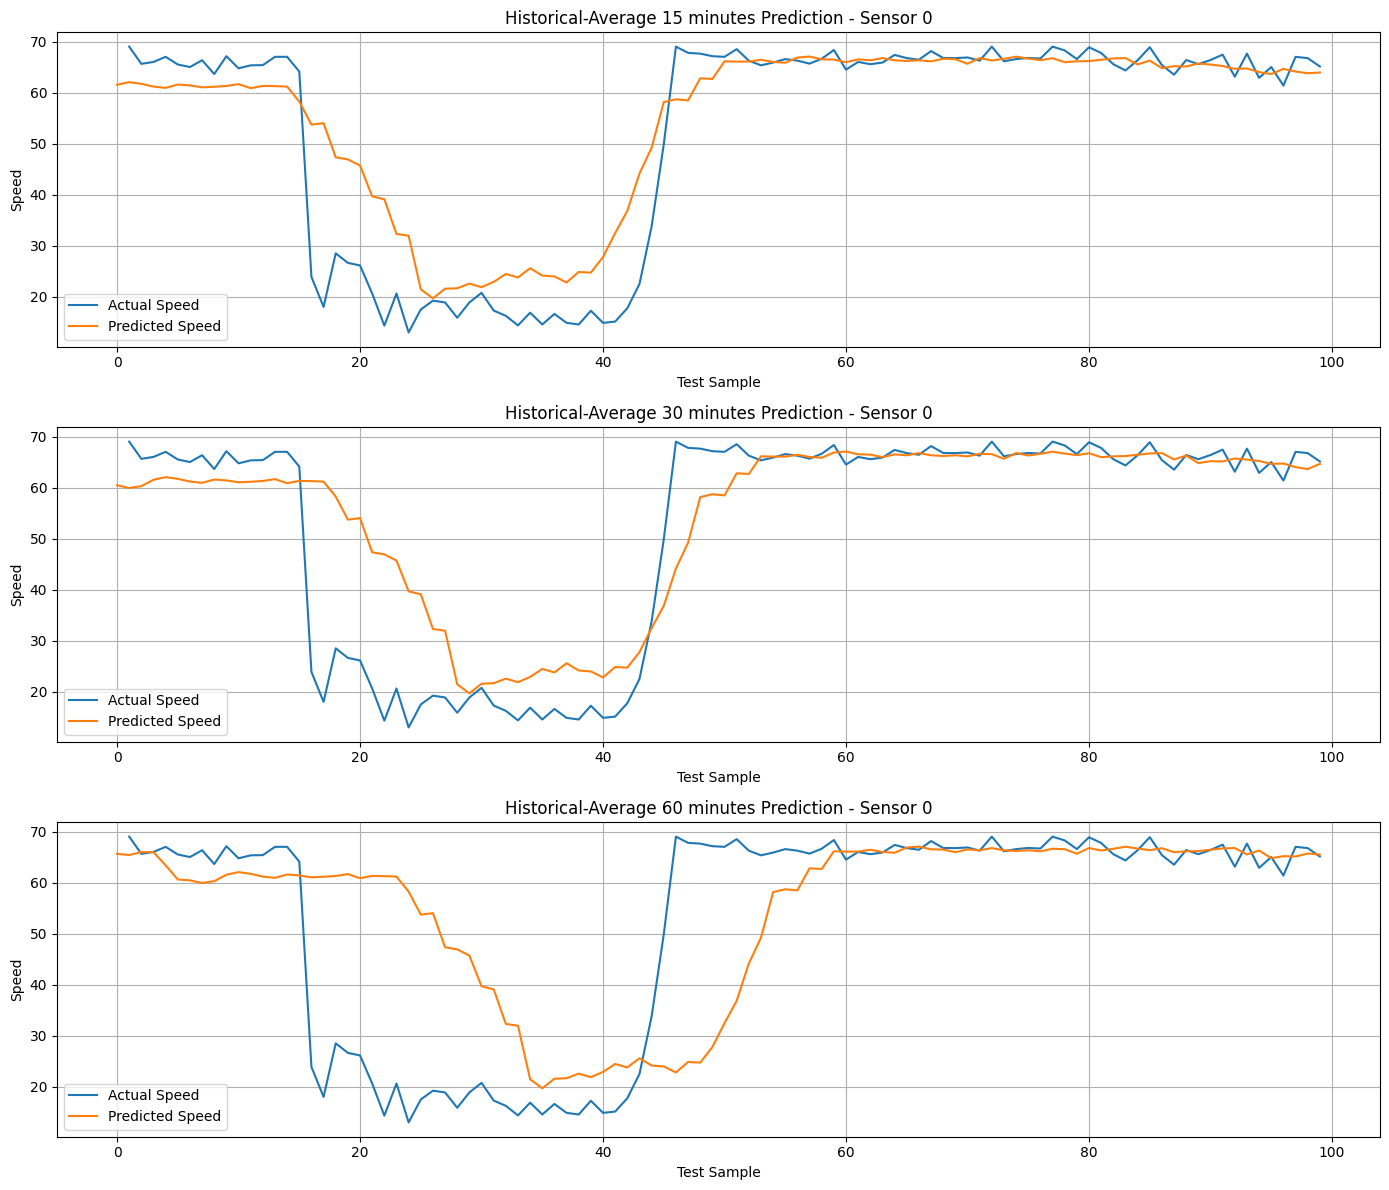

Saved: /content/historical_average_results/historical_average_prediction_comparison.png


In [12]:
sensor_id = 0
num_points = 100

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 12)
)

for ax, (horizon_name, steps) in zip(
    axes,
    horizons.items()
):
    y_true = actual[steps:, sensor_id]
    y_pred = predictions[:-steps, sensor_id]

    y_true = y_true[-num_points:]
    y_pred = y_pred[-num_points:]

    ax.plot(
        y_true,
        label="Actual Speed"
    )
    ax.plot(
        y_pred,
        label="Predicted Speed"
    )

    ax.set_title(
        "Historical-Average "
        + horizon_name.replace("_", " ")
        + " Prediction - Sensor 0"
    )
    ax.set_xlabel("Test Sample")
    ax.set_ylabel("Speed")
    ax.legend()
    ax.grid(True)

plt.tight_layout()

figure_path = os.path.join(
    RESULTS_DIR,
    "historical_average_prediction_comparison.png"
)

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved:", figure_path)

### Verify the files

In [13]:
print("Metrics file exists:",
      os.path.exists(metrics_path))

print("Figure exists:",
      os.path.exists(figure_path))

print("\nFinal metrics:")
display(results_table.round(4))

Metrics file exists: True
Figure exists: True

Final metrics:


,MAE,RMSE,MAPE
Horizon,,,
15_minutes,4.2846,7.9921,13.2415
30_minutes,4.5184,8.3833,13.8754
60_minutes,5.1756,9.5160,15.7827


### Download the files

In [14]:
from google.colab import files

files.download(metrics_path)
files.download(figure_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>